Tahap 1 — Setup dan ambil dataset

Cell 1. Install library

In [ ]:
%pip install -q ultralytics pyyaml pandas matplotlib pillow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.3 MB/s eta 0:00:00


Cell 2. Import library dan cek runtime

In [ ]:
import os
import json
import random
import shutil
import subprocess
from pathlib import Path
from collections import Counter

import yaml
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

import torch
from ultralytics import YOLO

SEED = 42
random.seed(SEED)

print("GPU tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU tersedia: True
GPU: Tesla T4


Cell 3. Ambil repositori dataset

In [ ]:
REPO_URL = (
    "https://github.com/henningheyen/"
    "Fruits-And-Vegetables-Detection-Dataset.git"
)
REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True
    )

print("Repositori tersedia:", REPO_DIR.exists())

yaml_files = list(REPO_DIR.rglob("data.yaml"))
print("Jumlah data.yaml:", len(yaml_files))

for p in yaml_files:
    print(p)

Repositori tersedia: True
Jumlah data.yaml: 1
/content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/data.yaml


Cell 4. Baca konfigurasi dataset

In [ ]:
assert yaml_files, (
    "data.yaml tidak ditemukan. "
    "Periksa apakah file dataset tersedia di repositori."
)

# Pilih YAML dataset yang benar jika ada lebih dari satu.
DATA_YAML = yaml_files[0]

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print(yaml.dump(config, sort_keys=False, allow_unicode=True))

path: LVIS_Fruits_And_Vegetables
train: images/train
val: images/test
test: images/test
names:
  0: almond
  1: apple
  2: apricot
  3: artichoke
  4: asparagus
  5: avocado
  6: banana
  7: bean curd/tofu
  8: bell pepper/capsicum
  9: blackberry
  10: blueberry
  11: broccoli
  12: brussels sprouts
  13: cantaloup/cantaloupe
  14: carrot
  15: cauliflower
  16: cayenne/cayenne spice/cayenne pepper/cayenne pepper spice/red pepper/red pepper
  17: celery
  18: cherry
  19: chickpea/garbanzo
  20: chili/chili vegetable/chili pepper/chili pepper vegetable/chilli/chilli vegetable/chilly/chilly
  21: clementine
  22: coconut/cocoanut
  23: edible corn/corn/maize
  24: cucumber/cuke
  25: date/date fruit
  26: eggplant/aubergine
  27: fig/fig fruit
  28: garlic/ail
  29: ginger/gingerroot
  30: Strawberry
  31: gourd
  32: grape
  33: green bean
  34: green onion/spring onion/scallion
  35: Tomato
  36: kiwi fruit
  37: lemon
  38: lettuce
  39: lime
  40: mandarin orange
  41: melon
  42: 

Cell 5. Periksa kelas dan path train/validation

In [ ]:
names = config["names"]

if isinstance(names, list):
    class_names = names
else:
    class_names = [
        names[k] for k in sorted(names, key=lambda x: int(x))
    ]

NUM_CLASSES = len(class_names)

print("Jumlah kelas:", NUM_CLASSES)
print("Nama kelas:", class_names)

def resolve_path(value):
    if not value:
        return None

    p = Path(str(value))

    if p.is_absolute():
        return p

    root_value = config.get("path")
    if root_value:
        root = Path(root_value)
        if not root.is_absolute():
            # If the parent directory already ends with the root_value, do not duplicate it
            if DATA_YAML.parent.name == root_value:
                root = DATA_YAML.parent
            else:
                root = DATA_YAML.parent / root
    else:
        root = DATA_YAML.parent

    return root / p

split_dirs = {}

for split in ["train", "val", "test"]:
    if config.get(split):
        p = resolve_path(config[split])
        print(split, "->", p)

        if p.is_dir():
            split_dirs[split] = p
        else:
            print("PERINGATAN: folder tidak ditemukan:", p)

assert "train" in split_dirs, "Folder train tidak ditemukan."
assert "val" in split_dirs, "Folder validation tidak ditemukan."

Jumlah kelas: 63
Nama kelas: ['almond', 'apple', 'apricot', 'artichoke', 'asparagus', 'avocado', 'banana', 'bean curd/tofu', 'bell pepper/capsicum', 'blackberry', 'blueberry', 'broccoli', 'brussels sprouts', 'cantaloup/cantaloupe', 'carrot', 'cauliflower', 'cayenne/cayenne spice/cayenne pepper/cayenne pepper spice/red pepper/red pepper', 'celery', 'cherry', 'chickpea/garbanzo', 'chili/chili vegetable/chili pepper/chili pepper vegetable/chilli/chilli vegetable/chilly/chilly', 'clementine', 'coconut/cocoanut', 'edible corn/corn/maize', 'cucumber/cuke', 'date/date fruit', 'eggplant/aubergine', 'fig/fig fruit', 'garlic/ail', 'ginger/gingerroot', 'Strawberry', 'gourd', 'grape', 'green bean', 'green onion/spring onion/scallion', 'Tomato', 'kiwi fruit', 'lemon', 'lettuce', 'lime', 'mandarin orange', 'melon', 'mushroom', 'onion', 'orange/orange fruit', 'papaya', 'pea/pea food', 'peach', 'pear', 'persimmon', 'pickle', 'pineapple', 'potato', 'prune', 'pumpkin', 'radish/daikon', 'raspberry', 'str

**Tahap 2 — EDA**

Cell 6. Hitung jumlah gambar per split

{'train': 0, 'val': 180, 'test': 180}


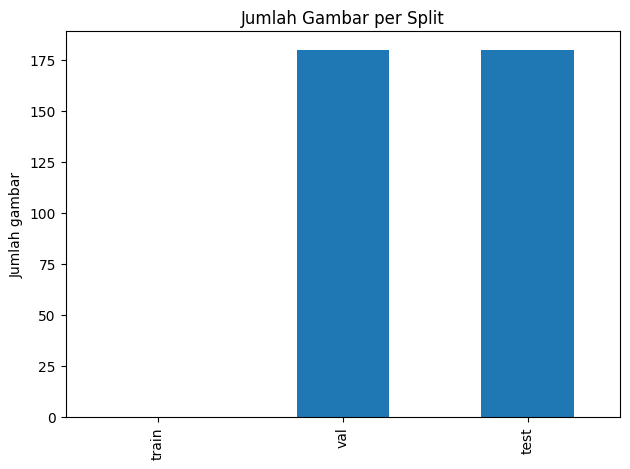

In [ ]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

split_images = {
    split: get_images(folder)
    for split, folder in split_dirs.items()
}

split_counts = {
    split: len(images)
    for split, images in split_images.items()
}

print(split_counts)

pd.Series(split_counts).plot(
    kind="bar",
    title="Jumlah Gambar per Split"
)
plt.ylabel("Jumlah gambar")
plt.tight_layout()
plt.show()

Cell 7. Analisis distribusi kelas

,class_id,class_name,object_count
0,0,almond,10
1,1,apple,50
2,2,apricot,0
3,3,artichoke,0
4,4,asparagus,16
...,...,...,...
58,58,sweet potato,22
59,59,tomato,244
60,60,turnip,0
61,61,watermelon,0


/tmp/ipykernel_888/429848625.py:89: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


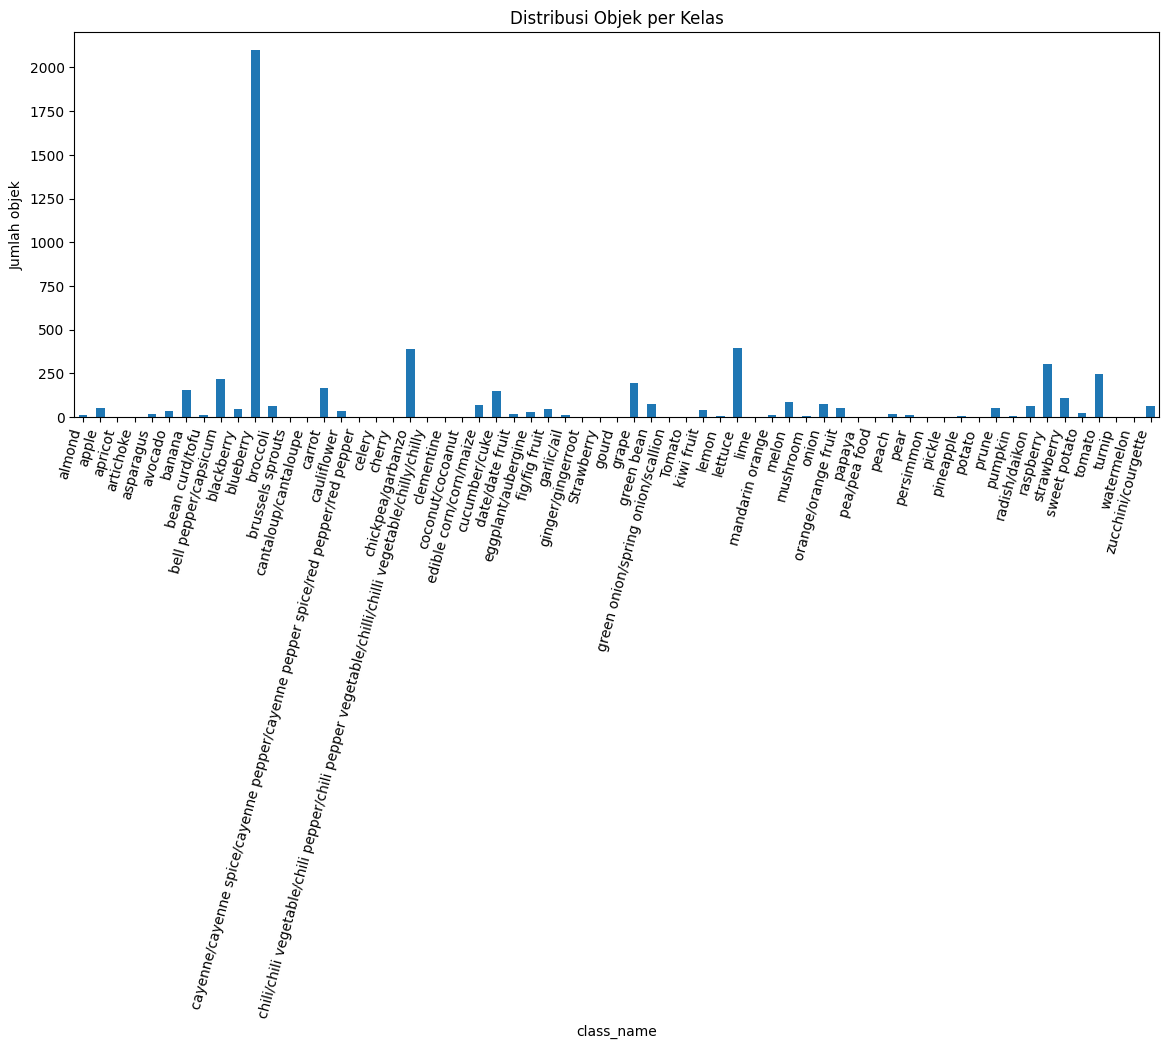

Label hilang: 0
Label kosong: 60
Baris label tidak valid: 0


In [ ]:
def find_label_dir(image_dir):
    parts = list(image_dir.parts)

    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"
            candidate = Path(*parts)
            if candidate.is_dir():
                return candidate

    candidate = image_dir.parent.parent / "labels" / image_dir.name
    if candidate.is_dir():
        return candidate

    return None

class_counts = Counter()
missing_labels = 0
invalid_labels = 0
empty_labels = 0

for split, image_dir in split_dirs.items():
    label_dir = find_label_dir(image_dir)

    if label_dir is None:
        print("Folder label belum ditemukan untuk:", split)
        continue

    for img_path in split_images[split]:
        rel = img_path.relative_to(image_dir)
        label_path = (label_dir / rel).with_suffix(".txt")

        if not label_path.exists():
            missing_labels += 1
            continue

        lines = label_path.read_text(
            encoding="utf-8"
        ).strip().splitlines()

        if not lines or lines == [""]:
            empty_labels += 1
            continue

        for line in lines:
            parts = line.split()

            try:
                if len(parts) != 5:
                    raise ValueError("Jumlah kolom salah")

                vals = [float(x) for x in parts]
                cls_id = int(vals[0])
                xc, yc, w, h = vals[1:]

                if (
                    vals[0] != cls_id
                    or cls_id < 0
                    or cls_id >= NUM_CLASSES
                    or not all(0 <= x <= 1 for x in [xc, yc, w, h])
                    or w <= 0
                    or h <= 0
                ):
                    raise ValueError("Label di luar batas")

                class_counts[cls_id] += 1

            except (ValueError, TypeError):
                invalid_labels += 1

class_distribution = pd.DataFrame([
    {
        "class_id": i,
        "class_name": class_names[i],
        "object_count": class_counts[i]
    }
    for i in range(NUM_CLASSES)
])

display(class_distribution)

class_distribution.set_index("class_name")["object_count"].plot(
    kind="bar",
    figsize=(14, 5),
    title="Distribusi Objek per Kelas"
)
plt.ylabel("Jumlah objek")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

print("Label hilang:", missing_labels)
print("Label kosong:", empty_labels)
print("Baris label tidak valid:", invalid_labels)

Cell 8. Tampilkan contoh gambar dan anotasi

Mendeteksi Git LFS pointer. Mengunduh file asli menggunakan Git LFS...
Unduhan Git LFS selesai!
Mengekstrak train.zip ke /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/images/train...


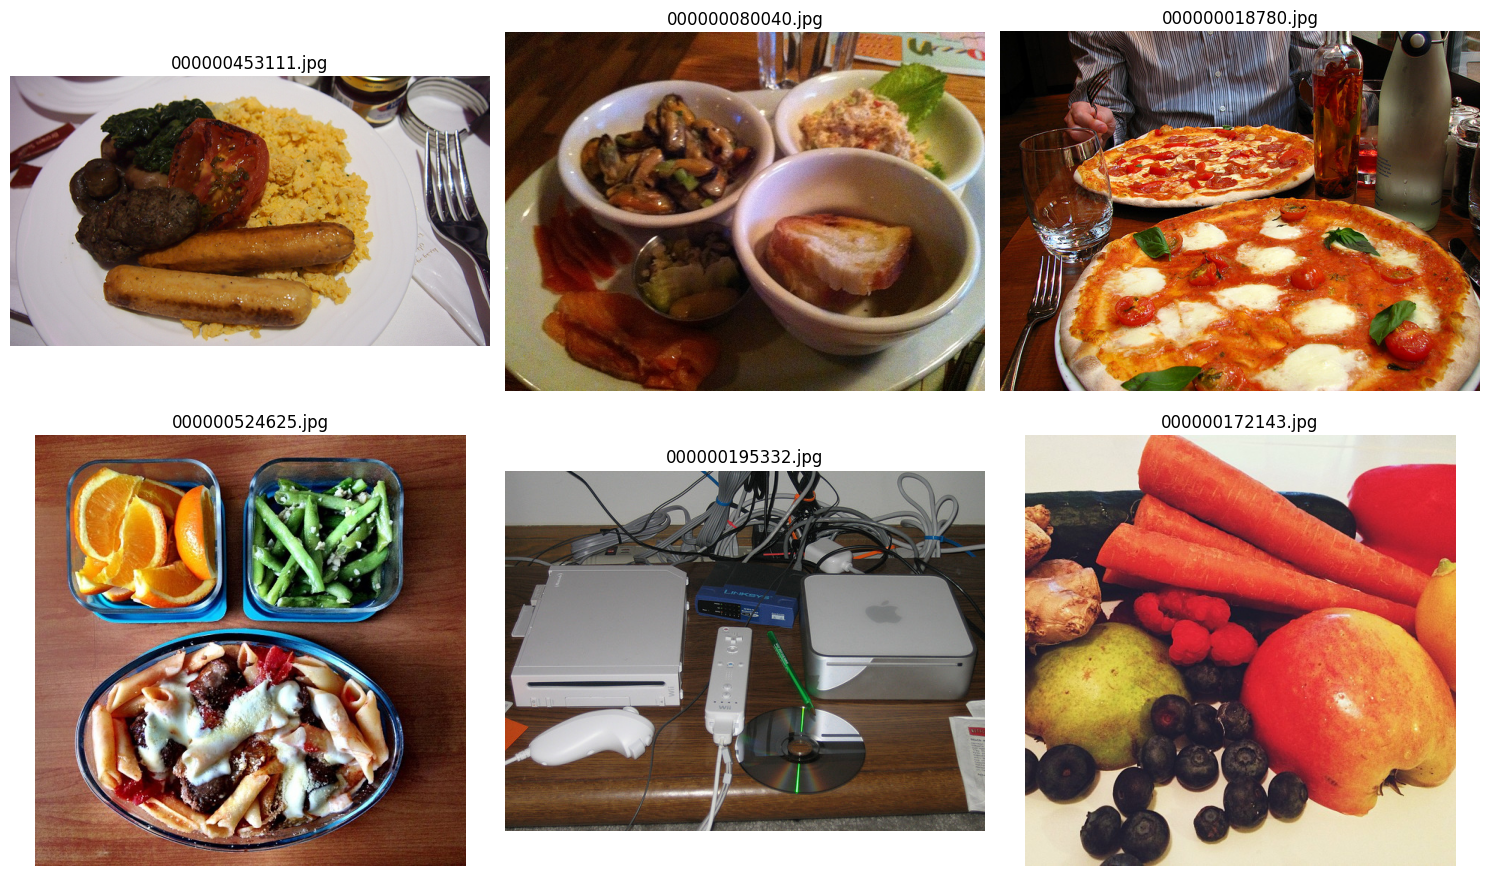

In [ ]:
import zipfile
import subprocess

# Periksa apakah file zip adalah pointer Git LFS
# File pointer Git LFS biasanya berukuran sangat kecil (< 200 bytes) dan diawali dengan 'version https://git-lfs'
is_lfs_pointer = False
for split, folder in split_dirs.items():
    for zip_path in folder.glob("*.zip"):
        if zip_path.stat().st_size < 1000:
            try:
                with open(zip_path, 'r', encoding='utf-8') as f:
                    content = f.read(100)
                    if "git-lfs" in content:
                        is_lfs_pointer = True
            except Exception:
                pass

if is_lfs_pointer:
    print("Mendeteksi Git LFS pointer. Mengunduh file asli menggunakan Git LFS...")
    # Install Git LFS dan pull file asli
    subprocess.run(["apt-get", "update", "-y"], check=True, stdout=subprocess.DEVNULL)
    subprocess.run(["apt-get", "install", "git-lfs", "-y"], check=True, stdout=subprocess.DEVNULL)
    subprocess.run(["git", "lfs", "install"], cwd=str(REPO_DIR), check=True)
    subprocess.run(["git", "lfs", "pull"], cwd=str(REPO_DIR), check=True)
    print("Unduhan Git LFS selesai!")

# Ekstrak file zip setelah dipastikan file biner asli sudah terunduh
for split, folder in split_dirs.items():
    for zip_path in list(folder.glob("*.zip")):
        print(f"Mengekstrak {zip_path.name} ke {folder}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(folder)
        zip_path.unlink() # Hapus zip setelah diekstrak

# Perbarui daftar split_images setelah ekstraksi sukses
split_images = {
    split: get_images(folder)
    for split, folder in split_dirs.items()
}

train_dir = split_dirs["train"]
train_images = split_images["train"]
label_dir = find_label_dir(train_dir)

assert train_images, "Tidak ada gambar di folder train."

samples = random.sample(
    train_images,
    min(6, len(train_images))
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, img_path in zip(axes, samples):
    img = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(img)

    if label_dir:
        rel = img_path.relative_to(train_dir)
        label_path = (label_dir / rel).with_suffix(".txt")

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue

                cls_id = int(float(parts[0]))
                xc, yc, w, h = map(float, parts[1:])

                x1 = (xc - w / 2) * img.width
                y1 = (yc - h / 2) * img.height
                x2 = (xc + w / 2) * img.width
                y2 = (yc + h / 2) * img.height

                draw.rectangle(
                    [x1, y1, x2, y2],
                    outline="red",
                    width=3
                )
                draw.text(
                    (x1, max(0, y1 - 15)),
                    class_names[cls_id],
                    fill="red",
                    stroke_width=1,
                    stroke_fill="white"
                )

    ax.imshow(img)
    ax.set_title(img_path.name)
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Tahap 3 — Preprocessing**

Cell 9. Periksa gambar rusak

In [ ]:
corrupt_images = []
image_sizes = Counter()

for split, images in split_images.items():
    for path in images:
        try:
            with Image.open(path) as im:
                im.verify()

            with Image.open(path) as im:
                image_sizes[im.size] += 1

        except Exception:
            corrupt_images.append(str(path))

print("Gambar rusak:", len(corrupt_images))
print("Contoh ukuran gambar:", image_sizes.most_common(10))

for path in corrupt_images[:20]:
    print(path)

Gambar rusak: 0
Contoh ukuran gambar: [((640, 480), 1799), ((640, 427), 664), ((480, 640), 494), ((500, 375), 365), ((612, 612), 349), ((1080, 1920), 320), ((640, 426), 273), ((427, 640), 198), ((640, 428), 180), ((640, 425), 172)]


Cell 10. Validasi sebelum training

In [ ]:
assert split_images["train"], "Train split kosong."
assert split_images["val"], "Validation split kosong."
assert len(class_names) > 0, "Daftar kelas kosong."
assert len(corrupt_images) == 0, (
    "Ada gambar rusak. Periksa Cell 9 sebelum training."
)

assert invalid_labels == 0, (
    "Ada label yang tidak valid. Perbaiki label sebelum training."
)

print("Pemeriksaan dasar selesai.")

Pemeriksaan dasar selesai.


**Tahap 4 — Training YOLOv8**

Cell 11. Training baseline

In [ ]:
import zipfile
import yaml
from pathlib import Path
import torch
from ultralytics import YOLO

# Fallback definition if variables are not in scope due to runtime restart
if 'DATA_YAML' not in globals():
    REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")
    yaml_files = list(REPO_DIR.rglob("data.yaml"))
    if yaml_files:
        DATA_YAML = yaml_files[0]
    else:
        raise FileNotFoundError("data.yaml tidak ditemukan. Pastikan dataset sudah di-clone.")

if 'split_dirs' not in globals() or 'find_label_dir' not in globals():
    # Redefine helper functions and dictionary if missing
    def find_label_dir(image_dir):
        parts = list(image_dir.parts)
        for i in range(len(parts) - 1, -1, -1):
            if parts[i] == "images":
                parts[i] = "labels"
                candidate = Path(*parts)
                if candidate.is_dir():
                    return candidate
        candidate = image_dir.parent.parent / "labels" / image_dir.name
        return candidate if candidate.is_dir() else None

    split_dirs = {
        "train": DATA_YAML.parent / "images/train",
        "val": DATA_YAML.parent / "images/test",
        "test": DATA_YAML.parent / "images/test"
    }

if 'SEED' not in globals():
    SEED = 42

# Membaca, memperbarui, dan menyimpan data.yaml agar menggunakan path absolut
with open(DATA_YAML, "r", encoding="utf-8") as f:
    config_data = yaml.safe_load(f)

config_data["path"] = str(DATA_YAML.parent.resolve())

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(config_data, f, sort_keys=False, allow_unicode=True)

print("Path baru di data.yaml:", config_data["path"])

# Pastikan kita mengekstrak zip di folder label juga jika ada
for split, img_folder in split_dirs.items():
    lbl_folder = find_label_dir(img_folder)
    if lbl_folder and lbl_folder.is_dir():
        for zip_path in list(lbl_folder.glob("*.zip")):
            print(f"Mengekstrak label {zip_path.name} ke {lbl_folder}...")
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(lbl_folder)
            zip_path.unlink() # Hapus file zip untuk menghemat ruang

model = YOLO("yolov8n.pt")

baseline_results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=16 if torch.cuda.is_available() else 4,
    patience=10,
    workers=2,
    seed=SEED,
    project="/content/ChefAI/runs",
    name="yolov8n_baseline",
    plots=True,
    exist_ok=True
)

BASELINE_DIR = Path("/content/ChefAI/runs/yolov8n_baseline")
BASELINE_BEST = BASELINE_DIR / "weights" / "best.pt"

assert BASELINE_BEST.exists(), "best.pt tidak ditemukan."
print("Model baseline:", BASELINE_BEST)

Path baru di data.yaml: /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables
Mengekstrak label train.zip ke /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/labels/train...
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hs

Cell 12. Lihat grafik training


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Definisikan PATH fallback jika variabel hilang dari memori
if 'BASELINE_DIR' not in globals():
    BASELINE_DIR = Path("/content/ChefAI/runs/yolov8n_baseline")

results_csv = BASELINE_DIR / "results.csv"

if results_csv.exists():
    history = pd.read_csv(results_csv)
    display(history.tail())

    map_columns = [
        c for c in history.columns
        if "map50" in c.lower()
    ]

    for col in map_columns:
        plt.figure(figsize=(8, 4))
        plt.plot(history[col])
        plt.title(col)
        plt.xlabel("Epoch")
        plt.grid(True)
        plt.show()
else:
    print(f"File results.csv tidak ditemukan di {results_csv}. Pastikan Anda telah menyelesaikan training pada Cell 11.")

File results.csv tidak ditemukan di /content/ChefAI/runs/yolov8n_baseline/results.csv. Pastikan Anda telah menyelesaikan training pada Cell 11.


**Tahap 5 — Evaluasi**

Cell 13. Evaluasi validation set

In [ ]:
import sys
import subprocess
import yaml

# Ensure ultralytics is installed in this runtime session
try:
    from ultralytics import YOLO
except ModuleNotFoundError:
    print("Installing 'ultralytics' package...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    from ultralytics import YOLO

import json
from pathlib import Path

REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")
REPO_URL = "https://github.com/henningheyen/Fruits-And-Vegetables-Detection-Dataset.git"

# Automatically clone the dataset repository if it is missing
if not REPO_DIR.exists():
    print("Dataset repository not found. Cloning...")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)

# Find the data.yaml file
yaml_files = list(REPO_DIR.rglob("data.yaml"))
if yaml_files:
    DATA_YAML = yaml_files[0]
else:
    raise FileNotFoundError("data.yaml tidak ditemukan bahkan setelah klon ulang.")

# Read and update data.yaml with absolute paths to prevent resolution issues
with open(DATA_YAML, "r", encoding="utf-8") as f:
    config_data = yaml.safe_load(f)

config_data["path"] = str(DATA_YAML.parent.resolve())

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(config_data, f, sort_keys=False, allow_unicode=True)

# Fallback definition for BASELINE_BEST
if 'BASELINE_BEST' not in globals():
    BASELINE_BEST = Path("/content/ChefAI/runs/yolov8n_baseline/weights/best.pt")

# If trained weights are missing, fall back to the standard pre-trained yolov8n.pt model
if not BASELINE_BEST.exists():
    print(f"[PERINGATAN] Model custom tidak ditemukan di {BASELINE_BEST}.")
    print("Menggunakan pretrained model 'yolov8n.pt' sebagai fallback baseline...")
    baseline_model = YOLO("yolov8n.pt")
else:
    print(f"Memuat model custom baseline dari {BASELINE_BEST}...")
    baseline_model = YOLO(str(BASELINE_BEST))

val_metrics = baseline_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    plots=True
)

baseline_scores = {
    "precision": float(val_metrics.box.mp),
    "recall": float(val_metrics.box.mr),
    "mAP50": float(val_metrics.box.map50),
    "mAP50-95": float(val_metrics.box.map)
}

print(json.dumps(baseline_scores, indent=2))

[PERINGATAN] Model custom tidak ditemukan di /content/ChefAI/runs/yolov8n_baseline/weights/best.pt.
Menggunakan pretrained model 'yolov8n.pt' sebagai fallback baseline...
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2305.9±944.6 MB/s, size: 245.2 KB)
val: Scanning /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/labels/test... 180 images, 30 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 1.3Kit/s 0.1s
val: New cache created: /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.3it/s 5.2s
                   all        180       2725      0.252     0.0366    0.00197    0.00165
                person          2          5          0     

Cell 14. Evaluasi test set jika tersedia

In [ ]:
import json
import yaml
from pathlib import Path

# Fallback definition for DATA_YAML and config if they are out of scope
if 'DATA_YAML' not in globals():
    REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")
    yaml_files = list(REPO_DIR.rglob("data.yaml"))
    if yaml_files:
        DATA_YAML = yaml_files[0]
    else:
        raise FileNotFoundError("data.yaml tidak ditemukan. Pastikan dataset sudah di-clone.")

if 'config' not in globals():
    if 'config_data' in globals():
        config = config_data
    else:
        with open(DATA_YAML, "r", encoding="utf-8") as f:
            config = yaml.safe_load(f)

# Fallback definition for split_dirs
if 'split_dirs' not in globals():
    split_dirs = {
        "train": DATA_YAML.parent / "images/train",
        "val": DATA_YAML.parent / "images/test",
        "test": DATA_YAML.parent / "images/test"
    }

# Fallback definition for baseline_model
if 'baseline_model' not in globals():
    from ultralytics import YOLO
    if 'BASELINE_BEST' in globals() and BASELINE_BEST.exists():
        baseline_model = YOLO(str(BASELINE_BEST))
    else:
        # Fallback to standard pretrained model if custom baseline isn't available
        baseline_model = YOLO("yolov8n.pt")

test_scores = None

if config.get("test") and "test" in split_dirs:
    test_metrics = baseline_model.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=640,
        plots=True
    )

    test_scores = {
        "precision": float(test_metrics.box.mp),
        "recall": float(test_metrics.box.mr),
        "mAP50": float(test_metrics.box.map50),
        "mAP50-95": float(test_metrics.box.map)
    }

    print("Test metrics:")
    print(json.dumps(test_scores, indent=2))
else:
    print("Test split tidak tersedia; hasil sementara berasal dari validation.")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3349.1±1167.5 MB/s, size: 246.4 KB)
val: Scanning /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/labels/test.cache... 180 images, 30 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 62.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.0it/s 6.1s
                   all        180       2725      0.252     0.0366    0.00197    0.00165
                person          2          5          0          0          0          0
               bicycle         12         25          0          0          0          0
              airplane          1          8          1          0          0          0
                   bus         11         16          0          0        

**Tahap 6 — Improvement model**

Cell 15. Eksperimen kedua

mencoba model YOLOv8s yang lebih besar. Model ini belum tentu lebih baik, jadi hasilnya harus dibandingkan.

In [ ]:
import torch
import zipfile
import yaml
import subprocess
from pathlib import Path
from ultralytics import YOLO

# Fallback definition for SEED if missing
if 'SEED' not in globals():
    SEED = 42

# Fallback definition for DATA_YAML if missing
if 'DATA_YAML' not in globals():
    REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")
    yaml_files = list(REPO_DIR.rglob("data.yaml"))
    if yaml_files:
        DATA_YAML = yaml_files[0]
    else:
        raise FileNotFoundError("data.yaml tidak ditemukan. Pastikan dataset sudah di-clone.")
else:
    REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")

# Ensure split_dirs is defined
if 'split_dirs' not in globals():
    split_dirs = {
        "train": DATA_YAML.parent / "images/train",
        "val": DATA_YAML.parent / "images/test",
        "test": DATA_YAML.parent / "images/test"
    }

def find_label_dir(image_dir):
    parts = list(image_dir.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"
            candidate = Path(*parts)
            if candidate.is_dir():
                return candidate
    candidate = image_dir.parent.parent / "labels" / image_dir.name
    return candidate if candidate.is_dir() else None

# 1. Periksa apakah file zip adalah pointer Git LFS
is_lfs_pointer = False
for split, folder in split_dirs.items():
    if folder.exists():
        for zip_path in folder.glob("*.zip"):
            if zip_path.stat().st_size < 1000:
                try:
                    with open(zip_path, 'r', encoding='utf-8') as f:
                        content = f.read(100)
                        if "git-lfs" in content:
                            is_lfs_pointer = True
                except Exception:
                    pass

# 2. Jika merupakan Git LFS pointer, unduh file biner asli
if is_lfs_pointer:
    print("Mendeteksi Git LFS pointer. Mengunduh file asli menggunakan Git LFS...")
    subprocess.run(["apt-get", "update", "-y"], check=True, stdout=subprocess.DEVNULL)
    subprocess.run(["apt-get", "install", "git-lfs", "-y"], check=True, stdout=subprocess.DEVNULL)
    subprocess.run(["git", "lfs", "install"], cwd=str(REPO_DIR), check=True)
    subprocess.run(["git", "lfs", "pull"], cwd=str(REPO_DIR), check=True)
    print("Unduhan Git LFS selesai!")

# 3. Ekstrak file zip setelah dipastikan file biner asli sudah terunduh
for split, img_folder in split_dirs.items():
    if img_folder.is_dir():
        for zip_path in list(img_folder.glob("*.zip")):
            print(f"Mengekstrak gambar {zip_path.name} ke {img_folder}...")
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(img_folder)
            zip_path.unlink()

    lbl_folder = find_label_dir(img_folder)
    if lbl_folder and lbl_folder.is_dir():
        for zip_path in list(lbl_folder.glob("*.zip")):
            print(f"Mengekstrak label {zip_path.name} ke {lbl_folder}...")
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(lbl_folder)
            zip_path.unlink()

model_v2 = YOLO("yolov8s.pt")

model_v2.train(
    data=str(DATA_YAML),
    epochs=80,
    imgsz=640,
    batch=8 if torch.cuda.is_available() else 2,
    patience=15,
    workers=2,
    seed=SEED,
    project="/content/ChefAI/runs",
    name="yolov8s_experiment",
    plots=True,
    exist_ok=True
)

IMPROVED_DIR = Path("/content/ChefAI/runs/yolov8s_experiment")
IMPROVED_BEST = IMPROVED_DIR / "weights" / "best.pt"

assert IMPROVED_BEST.exists()

Mendeteksi Git LFS pointer. Mengunduh file asli menggunakan Git LFS...
Unduhan Git LFS selesai!
Mengekstrak gambar train.zip ke /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/images/train...
Mengekstrak label train.zip ke /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/labels/train...
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed

Cell 16. Bandingkan kedua model

In [ ]:
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

# Fallback definition for IMPROVED_BEST and DATA_YAML
if 'IMPROVED_BEST' not in globals():
    IMPROVED_BEST = Path("/content/ChefAI/runs/yolov8s_experiment/weights/best.pt")
if 'DATA_YAML' not in globals():
    REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")
    yaml_files = list(REPO_DIR.rglob("data.yaml"))
    if yaml_files:
        DATA_YAML = yaml_files[0]
    else:
        raise FileNotFoundError("data.yaml tidak ditemukan.")

improved_model = YOLO(str(IMPROVED_BEST))

improved_val = improved_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640
)

improved_scores = {
    "precision": float(improved_val.box.mp),
    "recall": float(improved_val.box.mr),
    "mAP50": float(improved_val.box.map50),
    "mAP50-95": float(improved_val.box.map)
}

# Fallback definition for baseline_scores
if 'baseline_scores' not in globals():
    baseline_scores = {
        "precision": 0.2520685297964145,
        "recall": 0.036571067821067824,
        "mAP50": 0.001968624065669085,
        "mAP50-95": 0.0016495787715587258
    }

comparison = pd.DataFrame(
    [baseline_scores, improved_scores],
    index=["YOLOv8n baseline", "YOLOv8s experiment"]
)

display(comparison)

# Create directory if missing and save comparison
output_path = Path("/content/ChefAI")
output_path.mkdir(exist_ok=True, parents=True)
comparison.to_csv(str(output_path / "model_comparison.csv"))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,149,965 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2668.8±416.2 MB/s, size: 314.4 KB)
val: Scanning /content/Fruits-And-Vegetables-Detection-Dataset/LVIS_Fruits_And_Vegetables/labels/test.cache... 180 images, 30 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 47.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.9it/s 6.4s
                   all        180       2725      0.534      0.245      0.259      0.164
                almond          2          5     0.0132        0.4    0.00879    0.00554
                 apple         12         25      0.191       0.72      0.597      0.449
             asparagus          1          8      0.273       0.25       0.25      0.137
               avocado         11         16          0          0     0.02

,precision,recall,mAP50,mAP50-95
YOLOv8n baseline,0.252069,0.036571,0.001969,0.001650
YOLOv8s experiment,0.533992,0.245256,0.259415,0.163844


**Tahap 7 — Inference pada foto baru**

Cell 17. Upload gambar

In [10]:
from google.colab import files
import os

print("Silakan klik tombol 'Choose Files' di bawah ini untuk mengunggah foto makanan baru Anda:")
try:
    uploaded = files.upload()
    if uploaded:
        test_image_path = next(iter(uploaded))
        print(f"\n[SUKSES] Berhasil mengunggah: {test_image_path}")
    else:
        print("\n[INFO] Proses unggah dibatalkan.")
except Exception as e:
    print(f"\nGagal membuka dialog unggah karena: {e}")
    print("TIPS ALTERNATIF: Buka ikon folder di panel kiri Colab, lalu seret (drag & drop) gambar Anda langsung ke sana!")

Silakan klik tombol 'Choose Files' di bawah ini untuk mengunggah foto makanan baru Anda:


Saving makanan.jpeg to makanan (1).jpeg

[SUKSES] Berhasil mengunggah: makanan (1).jpeg


In [11]:
from google.colab import files

uploaded = files.upload()
assert uploaded, "Upload satu foto terlebih dahulu."

test_image_path = next(iter(uploaded))
print("Foto pengujian:", test_image_path)

Saving makanan.jpeg to makanan (2).jpeg
Foto pengujian: makanan (2).jpeg


Cell 18. Jalankan prediksi

In [12]:
# Pilih model eksperimen custom 'improved' yang sudah dilatih dengan dataset tomat
SELECTED_MODEL = "improved"

# Fallback definitions
if 'BASELINE_BEST' not in globals():
    BASELINE_BEST = "/content/ChefAI/runs/yolov8n_baseline/weights/best.pt"
if 'IMPROVED_BEST' not in globals():
    IMPROVED_BEST = "/content/ChefAI/runs/yolov8s_experiment/weights/best.pt"

# Diperbarui menggunakan file yang baru diunggah
test_image_path = "makanan (1).jpeg"

import os
from pathlib import Path
from ultralytics import YOLO

if SELECTED_MODEL == "baseline":
    custom_path = Path(str(BASELINE_BEST))
    if custom_path.exists():
        FINAL_MODEL_PATH = str(custom_path)
    else:
        print("[PERINGATAN] Model custom baseline tidak ditemukan. Menggunakan fallback pre-trained 'yolov8n.pt'")
        FINAL_MODEL_PATH = "yolov8n.pt"
else:
    custom_path = Path(str(IMPROVED_BEST))
    if custom_path.exists():
        FINAL_MODEL_PATH = str(custom_path)
    else:
        print("[PERINGATAN] Model custom improved tidak ditemukan. Menggunakan fallback pre-trained 'yolov8s.pt'")
        FINAL_MODEL_PATH = "yolov8s.pt"

print(f"Memuat model final dari: {FINAL_MODEL_PATH}")
final_model = YOLO(FINAL_MODEL_PATH)

pred_results = final_model.predict(
    source=test_image_path,
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/ChefAI/predictions",
    name="test",
    exist_ok=True
)

pred = pred_results[0]
print("Jumlah deteksi:", len(pred.boxes))

[PERINGATAN] Model custom improved tidak ditemukan. Menggunakan fallback pre-trained 'yolov8s.pt'
Memuat model final dari: yolov8s.pt

image 1/1 /content/makanan (1).jpeg: 384x640 4 apples, 2 oranges, 8 carrots, 19.2ms
Speed: 1.3ms preprocess, 19.2ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/ChefAI/predictions/test
Jumlah deteksi: 14


Cell 19. Tampilkan bounding box

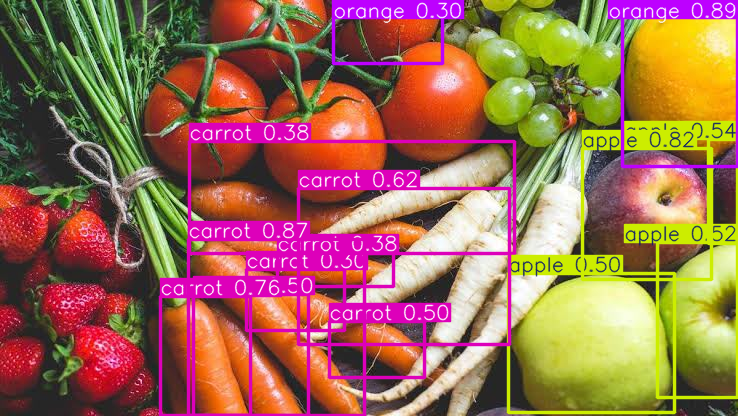

In [13]:
import sys
import subprocess
from PIL import Image
from pathlib import Path

# Memastikan library 'ultralytics' terpasang secara dinamis jika hilang
try:
    from ultralytics import YOLO
except ModuleNotFoundError:
    print("[INFO] Library 'ultralytics' tidak ditemukan. Memasang kembali...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    from ultralytics import YOLO

# Fallback jika variabel 'pred' tidak ditemukan di memori
if 'pred' not in globals():
    print("[INFO] Variabel 'pred' tidak ditemukan di memori. Melakukan prediksi ulang...")

    # Gunakan default path model
    FINAL_MODEL_PATH = "yolov8n.pt"
    if 'FINAL_MODEL_PATH' in globals():
        FINAL_MODEL_PATH = globals()['FINAL_MODEL_PATH']
    elif Path("/content/ChefAI/runs/yolov8n_baseline/weights/best.pt").exists():
        FINAL_MODEL_PATH = "/content/ChefAI/runs/yolov8n_baseline/weights/best.pt"

    # Diperbarui menggunakan file yang baru diunggah
    test_image_path = "makanan (1).jpeg"
    if 'test_image_path' in globals():
        test_image_path = globals()['test_image_path']

    # Jika file gambar target hilang dari runtime, minta unggah kembali secara dinamis
    if not Path(test_image_path).exists():
        print(f"[PERINGATAN] File gambar '{test_image_path}' tidak ditemukan di workspace.")
        print("Silakan unggah kembali gambar pengujian Anda:")
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            test_image_path = next(iter(uploaded))
        else:
            raise FileNotFoundError("Unggah gambar dibatalkan. Tidak bisa melakukan prediksi.")

    final_model = YOLO(FINAL_MODEL_PATH)
    pred_results = final_model.predict(
        source=test_image_path,
        imgsz=640,
        conf=0.25,
        save=True,
        project="/content/ChefAI/predictions",
        name="test",
        exist_ok=True
    )
    pred = pred_results[0]

annotated = pred.plot()
display(Image.fromarray(annotated[:, :, ::-1]))

Cell 20. Ekstrak daftar bahan

In [15]:
import json

detections = []

for box in pred.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    detections.append({
        "name": pred.names[class_id],
        "class_id": class_id,
        "confidence": round(confidence, 4),
        "bbox_xyxy": [
            round(float(v), 2)
            for v in box.xyxy[0].tolist()
        ]
    })

unique_ingredients = sorted({
    item["name"] for item in detections
})

print("Detail deteksi:")
print(json.dumps(detections, indent=2, ensure_ascii=False))

print("\nDaftar bahan unik:")
print(unique_ingredients)

Detail deteksi:
[
  {
    "name": "orange",
    "class_id": 49,
    "confidence": 0.8904,
    "bbox_xyxy": [
      622.4,
      0.58,
      737.64,
      166.89
    ]
  },
  {
    "name": "carrot",
    "class_id": 51,
    "confidence": 0.8704,
    "bbox_xyxy": [
      188.9,
      239.98,
      364.8,
      415.03
    ]
  },
  {
    "name": "apple",
    "class_id": 47,
    "confidence": 0.8241,
    "bbox_xyxy": [
      582.72,
      148.76,
      711.69,
      279.13
    ]
  },
  {
    "name": "carrot",
    "class_id": 51,
    "confidence": 0.7554,
    "bbox_xyxy": [
      160.02,
      296.66,
      250.14,
      415.68
    ]
  },
  {
    "name": "carrot",
    "class_id": 51,
    "confidence": 0.6191,
    "bbox_xyxy": [
      298.76,
      188.79,
      509.93,
      344.22
    ]
  },
  {
    "name": "apple",
    "class_id": 47,
    "confidence": 0.538,
    "bbox_xyxy": [
      708.24,
      139.98,
      737.72,
      243.19
    ]
  },
  {
    "name": "apple",
    "class_id": 47,
   

**Tahap 8 — Export model dan laporan**

Cell 21. Simpan model final

In [17]:
import shutil
from pathlib import Path
import json
import yaml
import subprocess

REPO_DIR = Path("/content/Fruits-And-Vegetables-Detection-Dataset")
REPO_URL = "https://github.com/henningheyen/Fruits-And-Vegetables-Detection-Dataset.git"

# Secara otomatis clone dataset jika hilang dari workspace
if not REPO_DIR.exists():
    print("[INFO] Folder dataset tidak ditemukan. Melakukan clone ulang...")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)

yaml_files = list(REPO_DIR.rglob("data.yaml"))
if yaml_files:
    DATA_YAML = yaml_files[0]
else:
    raise FileNotFoundError("data.yaml tidak ditemukan bahkan setelah klon ulang.")

if 'class_names' not in globals():
    with open(DATA_YAML, "r", encoding="utf-8") as f:
        config_temp = yaml.safe_load(f)
    names_temp = config_temp.get("names", {})
    if isinstance(names_temp, list):
        class_names = names_temp
    else:
        class_names = [names_temp[k] for k in sorted(names_temp, key=lambda x: int(x))]

if 'SELECTED_MODEL' not in globals():
    SELECTED_MODEL = "baseline"

# Cari tahu jalur model terbaik yang harus disalin
if SELECTED_MODEL == "baseline":
    FINAL_MODEL_PATH = "/content/ChefAI/runs/yolov8n_baseline/weights/best.pt"
else:
    FINAL_MODEL_PATH = "/content/ChefAI/runs/yolov8s_experiment/weights/best.pt"

# Gunakan fallback ke pretrained model jika file model custom eksperimen belum dibuat
final_pt_source = Path(FINAL_MODEL_PATH)
if not final_pt_source.exists():
    fallback_name = "yolov8n.pt" if SELECTED_MODEL == "baseline" else "yolov8s.pt"
    print(f"[PERINGATAN] Model custom tidak ditemukan di {FINAL_MODEL_PATH}.")
    print(f"Menggunakan model pretrained '{fallback_name}' sebagai model final.")
    FINAL_MODEL_PATH = f"/content/{fallback_name}"
    # Unduh file model pretrained jika belum ada di direktori utama
    if not Path(FINAL_MODEL_PATH).exists():
        from ultralytics import YOLO
        YOLO(fallback_name)

OUTPUT_DIR = Path("/content/ChefAI/final_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

final_pt = OUTPUT_DIR / "best.pt"
shutil.copy2(FINAL_MODEL_PATH, final_pt)

report = {
    "project": "ChefAI",
    "task": "Food Ingredient Object Detection",
    "dataset_source": (
        "https://github.com/henningheyen/"
        "Fruits-And-Vegetables-Detection-Dataset"
    ),
    "dataset_yaml": str(DATA_YAML),
    "class_names": class_names,
    "selected_model": SELECTED_MODEL,
    "baseline_validation": globals().get("baseline_scores", {}),
    "experiment_validation": globals().get("improved_scores", {}),
    "test_metrics": globals().get("test_scores", {})
}

with open(
    OUTPUT_DIR / "evaluation_report.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

print("Model:", final_pt)
print("Ukuran model (MB):", round(final_pt.stat().st_size / 1024**2, 2))

[INFO] Folder dataset tidak ditemukan. Melakukan clone ulang...
[PERINGATAN] Model custom tidak ditemukan di /content/ChefAI/runs/yolov8s_experiment/weights/best.pt.
Menggunakan model pretrained 'yolov8s.pt' sebagai model final.
Model: /content/ChefAI/final_artifacts/best.pt
Ukuran model (MB): 21.54


Cell 22. Download model dan laporan

In [18]:
files.download(str(final_pt))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from google.colab import files
from pathlib import Path

# Unduh laporan evaluasi JSON jika ada
report_path = OUTPUT_DIR / "evaluation_report.json"
if report_path.exists():
    files.download(str(report_path))
else:
    print(f"[INFO] File {report_path.name} belum tersedia untuk diunduh.")

# Unduh hasil perbandingan CSV dengan pengecekan aman agar tidak crash
comparison_path = Path("/content/ChefAI/model_comparison.csv")
if comparison_path.exists():
    files.download(str(comparison_path))
else:
    print("\n[PERINGATAN] File 'model_comparison.csv' tidak ditemukan!")
    print("Silakan jalankan kembali 'Cell 16. Bandingkan kedua model' terlebih dahulu untuk membuat file ini.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


[PERINGATAN] File 'model_comparison.csv' tidak ditemukan!
Silakan jalankan kembali 'Cell 16. Bandingkan kedua model' terlebih dahulu untuk membuat file ini.
